# T04 — Frequency response and the rho-f model

Between 0 Hz and 1 kHz the impedance of a networked grounding system
changes with frequency, and it changes with the soil resistivity. A
planner who works with a network model (for example
[groundinsight](https://github.com/Ce1ectric/groundinsight)) does not
want to rerun a field solution for every soil and every harmonic; he
needs a compact formula $Z(\rho, f)$ — the **rho-f model**. This
tutorial computes the frequency response of a small LV network, shows
how much the earth-return model matters, and reduces the results to a
rho-f formula in two ways: the six-coefficient *standard form* over
$\rho$ and $f$, and a *vector fit* over $f$ at one resistivity. Every
fit is checked on data it has not seen.

**You will learn**

- where the frequency dependence below 1 kHz comes from, and how to
  switch it on (`inductance_model="neumann"`);
- the three earth-return models and when to use which;
- how to fit, evaluate and validate the standard rho-f form and a
  vector fit, and how to read their quality figures.

Runtime: about 10–20 s.

## Where the frequency dependence comes from

Below 1 kHz the soil itself stays quasi-static: the displacement
current is negligible and an earth electrode is a resistance. What
changes with frequency are the **conductors** that connect the
electrodes. A PEN cable of length $l$ has the series impedance

$$
Z_\mathrm{PEN}(\omega) = R + j\omega L + \Delta Z_\mathrm{earth}(\omega),
$$

where $L$ follows from the Neumann double integral over the cable
segments,
$M_{ij} = \frac{\mu_0}{4\pi} \int_i \int_j
\frac{\mathrm d\mathbf l \cdot \mathrm d\mathbf l'}{|\mathbf r - \mathbf r'|}$,
and $\Delta Z_\mathrm{earth}$ is the effect of the current that
returns through the conducting earth. As the frequency rises, the
cable reactance grows and the remote houses contribute less: the
network impedance seen from the substation rises.

`groundfield` offers three earth-return models
(`Engine.earth_inductive_model`):

| Model | Physics | Use |
|---|---|---|
| `"sommerfeld"` (default) | Sommerfeld/Pollaczek integral of the conducting half-space or layered earth over the real segment geometry | reference whenever $Z(f)$ matters |
| `"carson_series"` | Carson's (1926) per-metre earth-return correction for long parallel wires on the anti-parallel image | fast approximation for long parallel cables in homogeneous earth |
| `"perfect_mirror"` | the earth as a perfect magnetic mirror, frequency independent | diagnostic baseline only |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

import groundfield as gf

print("groundfield", gf.__version__)

RHO_AL = 2.82e-8  # Ohm m
FREQUENCIES = [
    0.0,
    50.0,
    150.0,
    250.0,
    350.0,
    450.0,
    550.0,
    650.0,
    750.0,
    850.0,
    1000.0,
]


def lv_network(rho=100.0, n_houses=4):
    # Substation earth plus houses on an inductive PEN chain (50 mm^2 Al).
    world = gf.create_world(soil=gf.HomogeneousSoil(rho=rho))
    gf.create_electrode(
        world,
        "grid_mesh",
        name="station",
        corner=(-2.0, -2.0, 0.6),
        size=(4.0, 4.0),
        n_x=1,
        n_y=1,
    )
    for k, (x, y) in enumerate([(-2.0, -2.0), (2.0, -2.0), (2.0, 2.0)]):
        gf.create_electrode(
            world, "rod", name=f"station_rod_{k}", position=(x, y, 0.6), length=4.0
        )
        gf.create_conductor(
            world, name=f"bond_{k}", start="station", end=f"station_rod_{k}"
        )
    previous = "station"
    for k in range(n_houses):
        x0 = 40.0 * (k + 1)
        gf.create_electrode(
            world,
            "grid_mesh",
            name=f"house_{k}",
            corner=(x0 - 5.0, 10.0, 0.8),
            size=(10.0, 10.0),
            n_x=1,
            n_y=1,
        )
        gf.create_conductor(
            world,
            name=f"pen_{k}",
            start=previous,
            end=f"house_{k}",
            conductor_type="pen",
            resistivity=RHO_AL,
            cross_section=50e-6,
            coupling_to_soil="isolated",
            inductance_model="neumann",  # self and mutual inductance of the cable
        )
        previous = f"house_{k}"
    gf.create_source(world, attached_to="station", magnitude=1.0)
    return world

groundfield 2026.11.0


## The frequency response and the earth-return model

One solve covers all frequencies of the engine. We solve the same
network with the three earth-return models.

sommerfeld      Z(0 Hz) = 1.3630 Ohm   Z(1 kHz) = 1.4899+0.6583j Ohm
carson_series   Z(0 Hz) = 1.3630 Ohm   Z(1 kHz) = 1.5627+0.7474j Ohm
perfect_mirror  Z(0 Hz) = 1.3630 Ohm   Z(1 kHz) = 1.5952+0.9270j Ohm


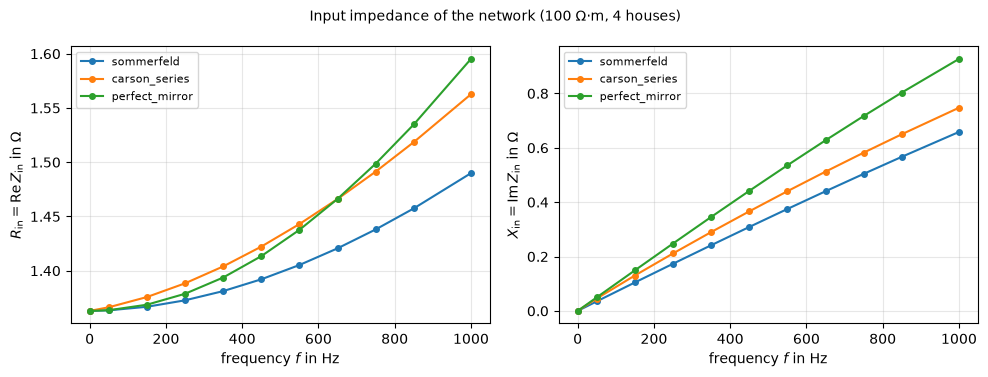

In [2]:
responses = {}
for model in ("sommerfeld", "carson_series", "perfect_mirror"):
    engine = gf.create_engine(
        segment_length=1.0, frequencies=FREQUENCIES, earth_inductive_model=model
    )
    responses[model] = np.array(engine.solve(lv_network()).input_impedance())

f = np.array(FREQUENCIES)
fig, (ax_r, ax_x) = plt.subplots(1, 2, figsize=(10, 3.8))
for model, z in responses.items():
    ax_r.plot(f, z.real, "o-", ms=4, label=model)
    ax_x.plot(f, z.imag, "o-", ms=4, label=model)
ax_r.set_ylabel(r"$R_\mathrm{in} = \mathrm{Re}\,Z_\mathrm{in}$ in $\Omega$")
ax_x.set_ylabel(r"$X_\mathrm{in} = \mathrm{Im}\,Z_\mathrm{in}$ in $\Omega$")
for ax in (ax_r, ax_x):
    ax.set_xlabel("frequency $f$ in Hz")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle("Input impedance of the network (100 Ω·m, 4 houses)", fontsize=10)
fig.tight_layout()

for model, z in responses.items():
    print(f"{model:15s} Z(0 Hz) = {z[0].real:.4f} Ohm   Z(1 kHz) = {z[-1]:.4f} Ohm")

In [3]:
z_dc = [z[0] for z in responses.values()]
assert all(abs(z - z_dc[0]) < 1e-12 for z in z_dc)  # 0 Hz: no inductive effect at all
assert all(abs(z[0].imag) < 1e-12 for z in responses.values())
assert all(
    np.all(np.diff(z.imag) > 0) for z in responses.values()
)  # reactance rises with f

At 0 Hz all three models give the same, purely resistive value. Above,
they disagree markedly: the earth-return model is not a detail.
`perfect_mirror` ignores the finite conductivity of the earth and is
kept only as a fast diagnostic baseline; `carson_series` is derived
for infinitely long parallel wires; `sommerfeld` integrates the
field of the conducting earth over the actual segment geometry and is
the default. We continue with `sommerfeld`.

## The resistivity sweep

We solve the network for three soils, $\rho \in \{100, 300, 1000\}\
\Omega\,\mathrm m$, to fit the model, and for two more,
$\rho \in \{200, 500\}\ \Omega\,\mathrm m$, that the fit never sees —
they are used to check its predictions.

In [4]:
engine = gf.create_engine(segment_length=1.0, frequencies=FREQUENCIES)  # sommerfeld
rho_fit = [100.0, 300.0, 1000.0]
rho_check = [200.0, 500.0]
results = {rho: engine.solve(lv_network(rho)) for rho in rho_fit + rho_check}
for rho in sorted(results):
    z = results[rho].input_impedance()
    print(
        f"rho = {rho:6.0f} Ohm m: Z(0 Hz) = {z[0].real:7.4f} Ohm, Z(1 kHz) = {z[-1]:.4f} Ohm"
    )

rho =    100 Ohm m: Z(0 Hz) =  1.3630 Ohm, Z(1 kHz) = 1.4899+0.6583j Ohm
rho =    200 Ohm m: Z(0 Hz) =  2.6944 Ohm, Z(1 kHz) = 2.7661+0.6891j Ohm
rho =    300 Ohm m: Z(0 Hz) =  4.0257 Ohm, Z(1 kHz) = 4.0765+0.6978j Ohm
rho =    500 Ohm m: Z(0 Hz) =  6.6883 Ohm, Z(1 kHz) = 6.7212+0.7042j Ohm
rho =   1000 Ohm m: Z(0 Hz) = 13.3447 Ohm, Z(1 kHz) = 13.3632+0.7091j Ohm


## The standard rho-f form

The research standard form describes the impedance with six real
coefficients,

$$
Z(\rho, f) = k_0 + k_1 \rho + (k_2 + j k_3)\, f + (k_4 + j k_5)\, f \rho .
$$

$k_0 + k_1\rho$ is the resistive part at 0 Hz, $k_3 f$ and $k_5 f \rho$
the reactance, $k_2 f$ and $k_4 f\rho$ the frequency-dependent
resistance. The fit minimises the error relative to $|Z|$ (weights
$1/|Z|$) over all samples and reports the worst pointwise relative
error `max_relative` next to the rms value. `rho_f_standard_from_results`
takes solved results and their resistivities; by default it fits the
input impedance.

In [5]:
fit = gf.rho_f_standard_from_results([results[rho] for rho in rho_fit], rho_fit)
for name in ("k0", "k1", "k2", "k3", "k4", "k5"):
    print(f"{name} = {getattr(fit, name):+.6e}")
print(f"fitted quantity: {fit.quantity}, weights: {fit.weights}")
print(f"rms relative error {fit.rms_relative:.2%}, worst sample {fit.max_relative:.2%}")
print("formula:", gf.fit_to_sympy_standard(fit, decimals=4))

k0 = +1.594443e-02
k1 = +1.333451e-02
k2 = +1.359809e-04
k3 = +6.653798e-04
k4 = -1.891348e-07
k5 = +7.507706e-08
fitted quantity: input, weights: relative
rms relative error 0.39%, worst sample 1.70%


formula: f*rho*(-1.891e-7 + 7.508e-8*I) + f*(0.000136 + 0.0006654*I) + 0.01333*rho + 0.01594


### Check: predictions for soils the fit has not seen

In [6]:
f = np.array(FREQUENCIES)
prediction_error = {}
for rho in rho_check:
    z_solved = np.array(results[rho].input_impedance())
    z_model = fit.evaluate(np.full(f.size, rho), f)
    prediction_error[rho] = np.max(np.abs(z_model / z_solved - 1.0))
    print(
        f"rho = {rho:4.0f} Ohm m: worst relative deviation of the formula {prediction_error[rho]:.2%}"
    )

rho =  200 Ohm m: worst relative deviation of the formula 0.82%
rho =  500 Ohm m: worst relative deviation of the formula 0.11%


In [7]:
assert fit.max_relative < 0.05
assert all(err < 0.02 for err in prediction_error.values())

### Know the limits of the standard form

The standard form is linear in $\rho$ at every frequency. That holds
for an earth electrode alone, whose resistance is proportional to
$\rho$, but not for a network: the cable resistance does not scale
with the soil, so at low resistivities it takes a larger share of the
impedance. Extending the fit down to $\rho = 30\ \Omega\,\mathrm m$
therefore degrades it, and the fit says so with a
`RhoFStandardQualityWarning` when the worst sample exceeds 5 %:

In [8]:
result_30 = engine.solve(lv_network(30.0))
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    wide = gf.rho_f_standard_from_results(
        [result_30] + [results[rho] for rho in rho_fit], [30.0] + rho_fit
    )
print(f"worst sample over 30 ... 1000 Ohm m: {wide.max_relative:.1%}")
for w in caught:
    print(f"{w.category.__name__}: {w.message}")

worst sample over 30 ... 1000 Ohm m: 11.2%


In [9]:
assert wide.max_relative > 0.05
assert any(issubclass(w.category, gf.RhoFStandardQualityWarning) for w in caught)

Fit the standard form over the resistivity range you need, check
`max_relative`, and use one vector fit per resistivity when a single
formula over $\rho$ is not accurate enough.

## Vector fitting at one resistivity

Vector fitting (Gustavsen and Semlyen, 1999) approximates the
frequency response by a rational function of $s = j\omega$,

$$
Z(s) = R_\infty + \sum_{k=1}^{n} \frac{r_k}{s - p_k},
$$

with poles $p_k$ and residues $r_k$ in conjugate pairs, so that the
model is real at $s = 0$ and causal. A physically sound grounding
model must also be **passive**: $\mathrm{Re}\,Z \geq 0$ at every
frequency, also between the samples. `check_passivity` scans the band
from 0 Hz to twice the highest fitted frequency.

We fit with one to three poles and, as an independent check, fit
again on the even-indexed frequencies only and predict the others.

In [10]:
result_100 = results[100.0]
z_100 = np.array(result_100.input_impedance())
train, test = slice(0, None, 2), slice(1, None, 2)

fits = {}
for n_poles in (1, 2, 3):
    vf = gf.rho_f_from_field_result(result_100, n_poles=n_poles)
    vf_train = gf.vector_fit(f[train], z_100[train], n_poles=n_poles)
    holdout = np.max(np.abs(vf_train.evaluate(f[test]) / z_100[test] - 1.0))
    report = gf.check_passivity(vf)
    fits[n_poles] = (vf, holdout, report)
    print(
        f"{n_poles} pole(s): rms relative {vf.rms_relative:.1e}, hold-out {holdout:.1e}, "
        f"passive: {report.passed} (min Re Z = {report.min_re_Z:.4f} Ohm at {report.f_at_min:.0f} Hz)"
    )

1 pole(s): rms relative 1.5e-03, hold-out 2.0e-03, passive: True (min Re Z = 1.3640 Ohm at 0 Hz)
2 pole(s): rms relative 1.9e-04, hold-out 2.6e-04, passive: True (min Re Z = 1.3631 Ohm at 0 Hz)
3 pole(s): rms relative 3.2e-05, hold-out 5.3e-05, passive: True (min Re Z = 1.3630 Ohm at 0 Hz)


In [11]:
for vf, holdout, report in fits.values():
    assert report.passed
    assert vf.rms_relative < 0.01 and holdout < 0.01
assert fits[2][0].rms_relative < fits[1][0].rms_relative

vector-fit formula, s = j 2 pi f: 5.3216 - 1.4667e+5/(s + 37379.0) - 200.61/(s + 5796.4)


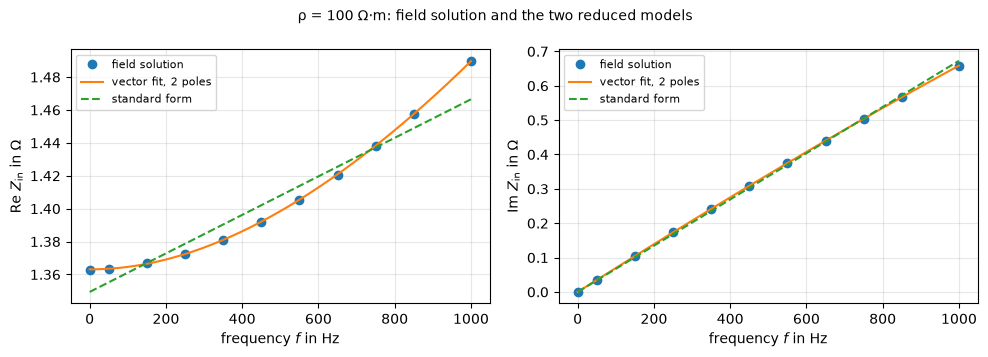

In [12]:
vf2 = fits[2][0]
f_dense = np.linspace(0.0, 1000.0, 201)
fig, (ax_r, ax_x) = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, part, label in ((ax_r, np.real, "Re"), (ax_x, np.imag, "Im")):
    ax.plot(f, part(z_100), "o", label="field solution")
    ax.plot(f_dense, part(vf2.evaluate(f_dense)), "-", label="vector fit, 2 poles")
    ax.plot(
        f_dense,
        part(fit.evaluate(np.full(f_dense.size, 100.0), f_dense)),
        "--",
        label="standard form",
    )
    ax.set_xlabel("frequency $f$ in Hz")
    ax.set_ylabel(rf"{label} $Z_\mathrm{{in}}$ in $\Omega$")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle("ρ = 100 Ω·m: field solution and the two reduced models", fontsize=10)
fig.tight_layout()
print("vector-fit formula, s = j 2 pi f:", gf.fit_to_sympy(vf2, decimals=5))

## Summary

- The frequency dependence below 1 kHz comes from the conductors;
  switch it on with `inductance_model="neumann"` and keep the default
  earth-return model `sommerfeld` for quantitative work.
- The standard rho-f form gives one formula for a range of soils;
  check `max_relative` and predictions at resistivities outside the
  fit. Vector fits describe one soil very accurately; check
  `rms_relative` and passivity.
- Fit the impedance you need: by default the helpers fit the input
  impedance (`quantity="input"`), the impedance a network model
  connects to.

**Next:** [T05 — export to groundinsight](T05_export_to_groundinsight.ipynb)
writes these models into a BusType that the network model reads.